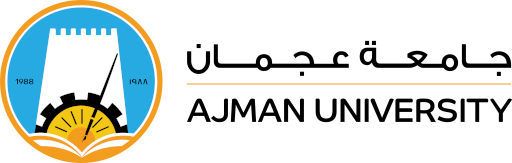

<p>
College: Engineering and Information Technology<br>
Department: Information Technology<br>
Program: Data Analytics<br>
Academic Semester: Spring 2025-2026<br>
Course: DAT405 Machine Learning Lab<br>
Course Instructor: Dr. Mahmoud AlShboul<br>
</p></center>

Student ID: _________________<br />
Student Name: _______________________

# **Lab 4: Machine Learning - Regression**

## Linear Regression

Linear regression is a basic and commonly used type of predictive analysis.  The overall idea of regression is to examine two things: (1) does a set of predictor variables do a good job in predicting an outcome (dependent) variable?  (2) Which variables in particular are significant predictors of the outcome variable, and in what way do they–indicated by the magnitude and sign of the beta estimates–impact the outcome variable?  These regression estimates are used to explain the relationship between one dependent variable and one or more independent variables.  The simplest form of the regression equation with one dependent and one independent variable is defined by the formula y = c + b*x, where y = estimated dependent variable score, c = constant, b = regression coefficient, and x = score on the independent variable.

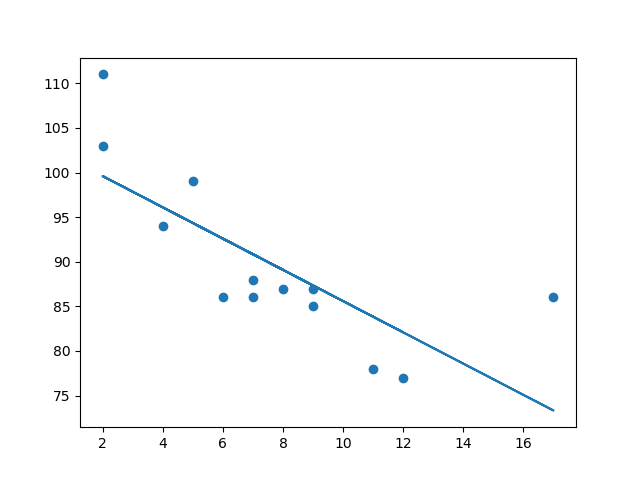

In [1]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, learning_curve
from sklearn import preprocessing
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import seaborn as sns

In [ ]:
# Load dataset "insurance.csv" for regression
df = pd.read_csv("/content/insurance.csv")
df

,age,gender,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [3]:
# Encode the categorical attributes gender, smoker, region
label_encoder = preprocessing.LabelEncoder()
df['gender'] = label_encoder.fit_transform(df['gender'])
df['smoker'] = label_encoder.fit_transform(df['smoker'])
df['region'] = label_encoder.fit_transform(df['region'])

# Preview the updated dataframe
df.head(10)

,age,gender,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,3,16884.92400
1,18,1,33.770,1,0,2,1725.55230
2,28,1,33.000,3,0,2,4449.46200
3,33,1,22.705,0,0,1,21984.47061
4,32,1,28.880,0,0,1,3866.85520
5,31,0,25.740,0,0,2,3756.62160
6,46,0,33.440,1,0,2,8240.58960
7,37,0,27.740,3,0,1,7281.50560
8,37,1,29.830,2,0,0,6406.41070
9,60,0,25.840,0,0,1,28923.13692


In [4]:
# Shape of the dataframe
df.shape

(1338, 7)

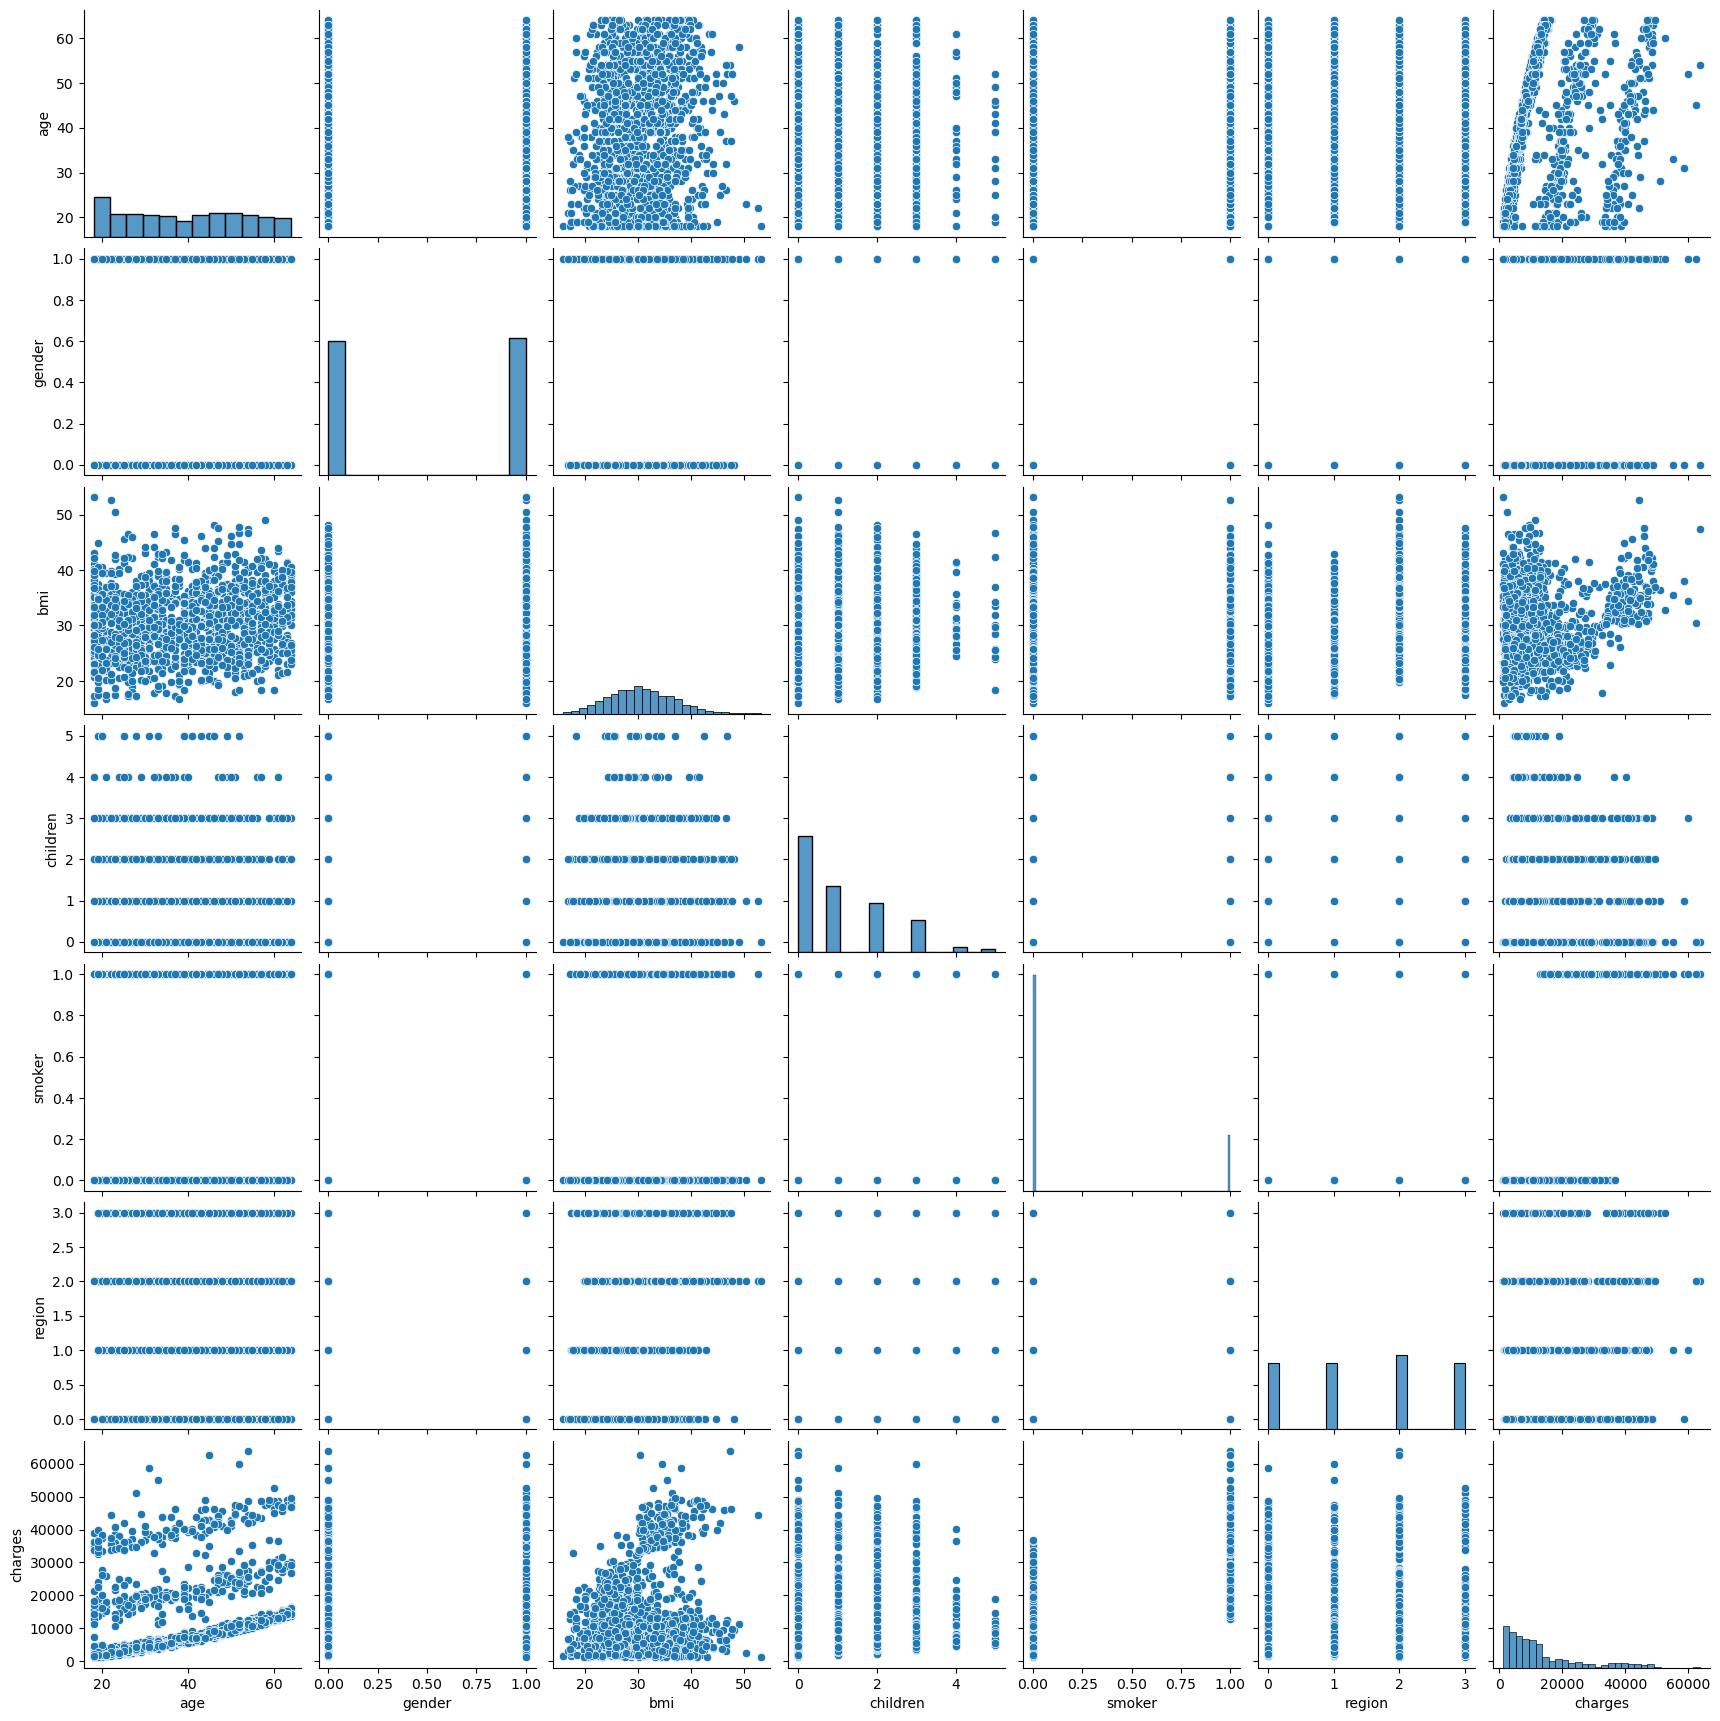

In [5]:
# Plot the pairplot of the dataframe
sns.pairplot(df)
# What this does:
# 1. Takes a DataFrame (df) as input.
# 2. Creates a grid of scatterplots for every pair of numerical features in the dataset.
#    - Each cell in the grid shows the relationship between two variables.
#    - For example, column A vs column B, column A vs column C, etc.
# 3. On the diagonal of the grid, it plots the distribution of each individual variable
#    (by default, a histogram or KDE plot).
# 4. Helps visualize:
#    - Correlations between variables
#    - Patterns or trends
#    - Potential outliers
#    - Separation of classes (if a 'hue' parameter is used)

In [6]:
# ===============================
# Data Preparation
# ===============================

# We separate the features (x) from the target (y).
# - x: all columns except 'charges'
# - y: the 'charges' column (the regression target)
x = df.drop(columns=['charges'])
y = df['charges']

# ===============================
# Step 1: Train-test split
# ===============================
# We split the dataset into training and testing sets.
# - test_size=0.25 → 25% test data, 75% training data
# - random_state=109 ensures reproducibility (same split every run).
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=109
)

# ===============================
# Step 2: Create and fit linear regression model
# ===============================
# Initialize a Linear Regression model
lr_model = LinearRegression()

# Train the model on the training data
lr_model.fit(x_train, y_train)

print(lr_model.score(x_test,y_test))

0.7265089860693381


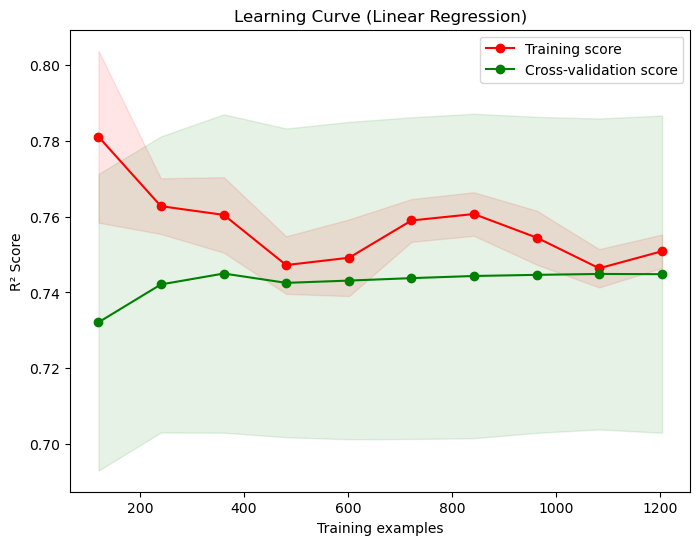

In [7]:
# ===============================
# Step 3: Plot learning curve
# ===============================
# The learning curve helps visualize how model performance changes as the training size increases.
# It shows:
# - Training score: model accuracy on training data
# - Validation score: model accuracy on unseen data (via cross-validation)


# A learning curve shows how a model’s performance changes as the
# size of the training data increases.
#
# X-axis → Number of training examples
# Y-axis → Performance metric (here, R² score)
#
# Two lines are plotted:
#   1. Training score (red curve):
#      - Model performance on training data
#      - Shows how well the model "memorizes" training data
#
#   2. Validation score (green curve):
#      - Model performance on unseen (cross-validation) data
#      - Shows how well the model generalizes to new data
#
# Interpretation:
# - High training score + low validation score → Overfitting
# - Both training and validation scores low → Underfitting
# - Both scores converge at a good value → Good generalization
# - If validation score improves as more data is added → more data could help


# R² Score (Coefficient of Determination) measures how well the regression model explains variability in the target (y).
#
# Formula:
# R² = 1 - (SS_res / SS_tot)
#   - SS_res = Sum of squared residuals (errors)
#   - SS_tot = Total variance in the target
#
# Interpretation:
# - R² = 1.0 → Perfect fit (model explains all variance)
# - R² = 0.0 → Model no better than predicting the mean of y
# - R² < 0   → Model performs worse than the mean baseline
# - Higher R² → Better fit (but watch for overfitting)


train_sizes, train_scores, test_scores = learning_curve(
    # The model to evaluate
    lr_model,
    # Full dataset (learning_curve handles internal resampling)
    x, y,
    # 10-fold cross-validation
    cv=10,
    # Metric for evaluation (R² score is default in regression tasks)
    scoring="r2",
    # Use 10 different training set sizes, from 10% to 100%
    train_sizes=np.linspace(0.1, 1.0, 10),
    # Ensures reproducibility of the cross-validation splits
    random_state=109
)

# ===============================
# Step 4: Calculate mean and std
# ===============================
# learning_curve returns scores for each fold in cross-validation.
# We compute the mean and standard deviation across folds to smooth the curve.
train_scores_mean = np.mean(train_scores, axis=1)
train_scores_std  = np.std(train_scores, axis=1)
test_scores_mean  = np.mean(test_scores, axis=1)
test_scores_std   = np.std(test_scores, axis=1)

# ===============================
# Step 5: Plotting
# ===============================
plt.figure(figsize=(8,6))
plt.title("Learning Curve (Linear Regression)")
plt.xlabel("Training examples")
plt.ylabel("R² Score")

# Plot the average training score as a red line with markers
plt.plot(
    train_sizes,
    train_scores_mean,
    'o-',
    color="r",
    label="Training score"
)

# Add a shaded region representing ±1 standard deviation for training scores
plt.fill_between(train_sizes,
                 train_scores_mean - train_scores_std,
                 train_scores_mean + train_scores_std,
                 alpha=0.1, color="r")

# Plot the average cross-validation (validation) score as a green line with markers
plt.plot(train_sizes, test_scores_mean, 'o-', color="g", label="Cross-validation score")

# Add shaded region for cross-validation scores
plt.fill_between(train_sizes,
                 test_scores_mean - test_scores_std,
                 test_scores_mean + test_scores_std,
                 alpha=0.1, color="g")

# Add legend to differentiate between training and validation curves
plt.legend(loc="best")

# Display the plot
plt.show()

### Implementation in Pycaret (Optional)

In [ ]:
# from pycaret.regression import RegressionExperiment
# s = RegressionExperiment()
# s.setup(df, target = 'charges', session_id = 109, train_size=0.75)
# # Creating the linear regression model
# lr_model = s.create_model('lr')
# # Plotting the feature importance
# s.plot_model(lr_model,'learning')

## SVR - Support Vector Regression
Support Vector Regression (SVR) is a supervised machine learning algorithm used for regression tasks. It is a variation of the Support Vector Machine (SVM) algorithm, which is primarily used for classification problems. SVR, on the other hand, is specifically designed to predict continuous target variables (numeric output) based on input features.

In [8]:
# Import Support Vector Regression (SVR) model
from sklearn.svm import SVR

# Import StandardScaler for feature scaling
# Scaling is important for SVR because it is sensitive to the magnitude of input values.
from sklearn.preprocessing import StandardScaler

# Create scaler objects for features (X) and target (y)
sc_X = StandardScaler()   # For scaling input features
sc_y = StandardScaler()   # For scaling target values (sometimes needed in SVR regression)

# We separate the features (x) from the target (y).
# - x: all columns except 'charges'
# - y: the 'charges' column (the regression target)
x = df.drop(columns=['charges'])
y = df['charges']

# ======================================
# Scaling the feature data
# ======================================
# Fit the StandardScaler to the feature matrix (x) and transform it.
# This standardizes the features by removing the mean and scaling to unit variance:
#   z = (x - mean) / standard_deviation
# Scaling ensures all features contribute equally to the SVR model.
x = sc_X.fit_transform(x)

# ======================================
# Splitting the dataset into training and testing sets
# ======================================
# We split the dataset into:
#   - Training set (75% of the data)
#   - Testing set (25% of the data)
#
# random_state=109 ensures reproducibility (the split is the same every run).
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=109
)


In [9]:
# ======================================
# Step 1: Initialize the SVR model
# ======================================
# - We are using Support Vector Regression (SVR) from scikit-learn.
# - The 'kernel' parameter defines how the model maps input data into higher dimensions:
#     * "linear"  → Fits a linear function (similar to LinearRegression, but with SVR margins).
#     * "rbf"     → Radial Basis Function kernel (non-linear, most common for SVR).
#     * "poly"    → Polynomial kernel (non-linear).
# - Here, we choose a linear kernel, so the model will try to fit a straight line (or hyperplane).
svr_model = SVR(kernel="linear")

# ======================================
# Step 2: Train the SVR model
# ======================================
# - The model is fit on the training set (x_train, y_train).
# - SVR tries to fit a function that predicts target values with an error tolerance (epsilon margin).
# - It does so by finding a hyperplane that balances prediction accuracy with model simplicity,
#   using support vectors (a subset of training points near the boundary).
svr_model.fit(x_train, y_train)

# ======================================
# Step 3: Evaluate model performance
# ======================================
# - .score() in regression returns the R² score (coefficient of determination).
# - R² measures how much variance in the target variable is explained by the model:
#     * R² = 1.0 → Perfect prediction
#     * R² = 0.0 → Model is no better than predicting the mean
#     * R² < 0   → Model performs worse than the mean baseline
# - Here, we test the trained model on the unseen test set (x_test, y_test).
print(svr_model.score(x_test, y_test))


-0.04035723219182885


## DTR - Decision Tree Regression
Decision tree regression is a supervised machine learning technique used for predictive modeling in regression tasks. It is a variation of the decision tree algorithm, which is commonly used for both classification and regression problems. Decision tree regression is specifically designed to predict a continuous target variable (numeric output) based on the values of one or more input features.

In [10]:
# ======================================
# Step 1: Import necessary libraries
# ======================================
# DecisionTreeRegressor → A regression model that predicts continuous values using decision trees.
# StandardScaler → Standardizes features by removing the mean and scaling to unit variance.
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler

# ======================================
# Step 2: Initialize scalers
# ======================================
# - sc_X will be used to scale the input features (independent variables).
# - sc_y is initialized to scale the target values (dependent variable),
#   but note: for Decision Trees, scaling is NOT required because they split data
#   based on thresholds and are invariant to monotonic transformations.
sc_X = StandardScaler()
sc_y = StandardScaler()

# ======================================
# Step 3: Separate features (x) and target (y)
# ======================================
# We separate the features (x) from the target (y).
# - x: all columns except 'charges'
# - y: the 'charges' column (the regression target)
x = df.drop(columns=['charges'])
y = df['charges']

# ======================================
# Step 4: Feature scaling
# ======================================
# - Scaling transforms the data so that each feature has mean = 0 and std = 1.
# - This is useful for models sensitive to feature scales (like SVM, KNN, Neural Nets).
# - Decision Trees, however, do NOT require scaling since they rely on threshold splits.
# - Still, scaling is applied here (possibly for experimentation).
x = sc_X.fit_transform(x)

# ======================================
# Step 5: Train-test split
# ======================================
# - Splits the dataset into training and testing sets.
# - x_train, y_train → used to train the model.
# - x_test, y_test   → held-out data to evaluate performance.
# - test_size = 0.25 → 25% of data for testing, 75% for training.
# - random_state=109 → ensures reproducibility (same split each run).
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=109)


In [11]:
# ======================================
# Step 6: Initialize the Decision Tree Regressor
# ======================================
# - By default, DecisionTreeRegressor() creates a regression tree that splits
#   data into regions and predicts continuous values.
# - It uses CART (Classification and Regression Trees) under the hood.
# - No hyperparameters are set here, so it uses defaults like:
#     * criterion="squared_error" → minimizes variance in regression.
#     * max_depth=None → tree expands until all leaves are pure or contain < min_samples_split samples.
#     * random_state=None → results may differ between runs.
dtr = DecisionTreeRegressor()

# ======================================
# Step 7: Train (fit) the model
# ======================================
# - The model learns from the training dataset (x_train, y_train).
# - The decision tree finds the best splits based on feature values to minimize prediction error.
# - After fitting, the model structure is fully built and ready for predictions.
dtr.fit(x_train, y_train)

# ======================================
# Step 8: Evaluate model performance
# ======================================
# - The .score() method for regressors returns the R² score (coefficient of determination).
# - R² = 1 → perfect predictions, R² = 0 → no better than predicting the mean,
#   negative values → model performs worse than simply predicting the mean of y_test.
# - Here, we check how well the trained tree predicts on the unseen test set.
print(dtr.score(x_test, y_test))


0.6655495304811465


### Implementation in Pycaret (Optional)

In [ ]:
# from pycaret.regression import RegressionExperiment
# s = RegressionExperiment()
# s.setup(df, target = 'charges', session_id = 109,train_size=0.75)
# # Creating the decision tree regressor model
# dt_model = s.create_model('dt')
# # Plotting the feature importance
# s.plot_model(dt_model,'learning')

# **Lab Assignment**
1. Load the 'jewellery.csv' dataset into a dataframe.
2. Visualize the pairplot and discuss some of the observed relationships between the variables.
3. Implement the three aforementioned models in whichever package you like, making sure the preprocessing and splits are consistent throughout the implementation of all three, discuss the observed results.

In [ ]:
# Your code
